<a href="https://colab.research.google.com/github/HimabinduBezawada/hello_world/blob/master/Hima_%7C_CLS_auto_%7C_Def_run_time.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

In [ ]:
#@title Resources | DONT RUN

moma code for gemini API integration here-
https://colab.sandbox.google.com/drive/1FMde92Jny3y_le4IIOmGIw7HBKb3oQri#scrollTo=TS9l5igubpHO

In [ ]:
#@title - Now actual project starts


In [ ]:
# @title Incrementality Test Reader (MVP)
# @markdown Fill in your test details and API key before running the cell:
test_media = "Google Ads Performance Max" # @param {type:"string"}
total_campaign_cost = 302465 # @param {type:"number"}
# gemini_api_key = "ENTER_YOUR_GEMINI_API_KEY_HERE" # @param {type:"string"}


In [ ]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
from matplotlib.backends.backend_pdf import PdfPages
import google.generativeai as genai
from google.colab import files
import textwrap
import io
import warnings
warnings.filterwarnings('ignore')

# Google Brand Colors
google_blue = '#4285F4'
google_red = '#EA4335'
google_yellow = '#FBBC04'
google_green = '#34A853'
google_grey = '#E0E0E0'

In [ ]:
# ---------------------------------------------------------
# 1. FILE UPLOAD
# ---------------------------------------------------------
print(f"--- Starting Incrementality Test Reader for {test_media} ---")
print("Please upload your raw incrementality dataset (.csv):")
uploaded = files.upload()
file_name = list(uploaded.keys())[0]

--- Starting Incrementality Test Reader for Parkdean Generic Search ---
Please upload your raw incrementality dataset (.csv):


Saving PArkdean_test_results.csv to PArkdean_test_results (2).csv


In [ ]:
# ---------------------------------------------------------
# 2. DATA PROCESSING & FILTERING
# ---------------------------------------------------------
df = pd.read_csv(io.BytesIO(uploaded[file_name]))

df['Analysis Date'] = pd.to_datetime(df['Analysis Date'])
latest_date = df['Analysis Date'].max()
df_latest = df[df['Analysis Date'] == latest_date]

df_top = df_latest[
    (df_latest['Country'].isin(['COUNTRY_ALL', 'All', 'ALL'])) &
    (df_latest['Age'].isin(['AGE_ALL', 'All', 'ALL'])) &
    (df_latest['Gender'].isin(['GENDER_ALL', 'All', 'ALL']))
]

df_conv = df_top[df_top['Report Type'] == 'conversion']
df_val = df_top[df_top['Report Type'] == 'conversion_value']

control_conv = df_conv['Scaled Control'].sum()
test_conv = df_conv['Treatment'].sum()

control_val = df_val['Scaled Control'].sum()
test_val = df_val['Treatment'].sum()

# Lift Calculations
abs_lift_conv = test_conv - control_conv
lift_conv = abs_lift_conv / control_conv if control_conv > 0 else 0

abs_lift_val = test_val - control_val
lift_val = abs_lift_val / control_val if control_val > 0 else 0

# Stat Sig Calculations
prob_lift_conv = df_conv['Probability of Lift'].mean()
is_sig_conv = prob_lift_conv >= 0.90 if pd.notnull(prob_lift_conv) else False

prob_lift_val = df_val['Probability of Lift'].mean()
is_sig_val = prob_lift_val >= 0.90 if pd.notnull(prob_lift_val) else False

In [ ]:
import pandas as pd

data = {
    'Metric': [
        'Conversions Control',
        'Conversions Test',
        'Conversions Lift',
        'Conversions Statistically Significant',
        'Conversions Probability of Lift',
        'Conversion Value Control',
        'Conversion Value Test',
        'Conversion Value Lift',
        'Conversion Value Statistically Significant',
        'Conversion Value Probability of Lift'
    ],
    'Value': [
        control_conv,
        test_conv,
        f'{lift_conv*100:.2f}%',
        is_sig_conv,
        f'{prob_lift_conv*100:.2f}%',
        control_val,
        test_val,
        f'{lift_val*100:.2f}%',
        is_sig_val,
        f'{prob_lift_val*100:.2f}%'
    ]
}

df_summary = pd.DataFrame(data)

# Display the DataFrame without the index for cleaner copying
print(df_summary.to_string(index=False))

                                    Metric   Value
                       Conversions Control   11996
                          Conversions Test   13464
                          Conversions Lift  12.24%
     Conversions Statistically Significant    True
           Conversions Probability of Lift 100.00%
                  Conversion Value Control 4438047
                     Conversion Value Test 4956786
                     Conversion Value Lift  11.69%
Conversion Value Statistically Significant    True
      Conversion Value Probability of Lift 100.00%


In [ ]:
# ---------------------------------------------------------
# 3. AI INSIGHT GENERATION (GEMINI)
# ---------------------------------------------------------
print("Crunching numbers and querying Gemini API for insights...")

# genai.configure(api_key=GEMINI_API_KEY)
# model = genai.GenerativeModel('gemini-1.5-flash')
####----------------------------


# Used to securely store your API key
from google.colab import userdata

from google.colab import userdata
userdata.get('secretName')

import os # Import the os module to set environment variables

# Or use `os.getenv('GEMINI_API_KEY')` to fetch an environment variable.
GOOGLE_API_KEY = userdata.get("GEMINI_API_KEY")

# Set the API key as an environment variable, which the genai library will pick up.
os.environ["GOOGLE_API_KEY"] = GOOGLE_API_KEY

genai.configure(api_key=GOOGLE_API_KEY)
# for m in genai.list_models():
#     if "generateContent" in m.supported_generation_methods:
#         print(m.name)

model = genai.GenerativeModel('gemini-2.5-flash')

Crunching numbers and querying Gemini API for insights...


In [ ]:
prompt = f"""
You are an expert performance marketing analyst. Review the following incrementality test results for "{test_media}":

COST:
- Total Campaign Cost: ${total_campaign_cost:,.2f}

CONVERSIONS:
- Control Group: {control_conv:,.0f}
- Test Group: {test_conv:,.0f}
- Lift: {lift_conv*100:.2f}%
- Statistically Significant: {"Yes" if is_sig_conv else "No"}

CONVERSION VALUE / REVENUE:
- Control Group: ${control_val:,.2f}
- Test Group: ${test_val:,.2f}
- Lift: {lift_val*100:.2f}%
- Statistically Significant: {"Yes" if is_sig_val else "No"}

Provide a professional <Test Insight> executive summary using 3 to 4 concise bullet points.
- Use a standard bullet character (•) for each point.
- Summarize the absolute numbers, ensuring all revenue and cost figures are formatted perfectly with a dollar sign ($) and commas for thousands.
- Interpret the lift and efficiency based on the cost.
- Conclude whether the test was successful based on the statistical significance.
Do not use Markdown bolding or italics (like **text**), as this will be printed as plain text in a PDF.
"""

try:
    response = model.generate_content(prompt)
    ai_insight = response.text.strip()
except Exception as e:
    ai_insight = f"• Error generating insight. Please check your API key.\n• Details: {e}"

In [ ]:
print(ai_insight)

<Test Insight>
• The Google Ads Performance Max campaign drove 13,464 conversions and $4,956,786.00 in revenue, compared to the control group's 11,996 conversions and $4,438,047.00 in revenue.
• For an investment of $302,465.00, the campaign delivered a statistically significant lift of 12.24% in conversions and 11.69% in conversion value.
• The incremental revenue generated by the campaign was $518,739.00, significantly outperforming the campaign cost and demonstrating strong efficiency.
• Based on the statistically significant positive lift in both conversions and revenue, this test proves the Google Ads Performance Max campaign was highly successful in driving incremental business value.


Generating charts and exporting to PDF...


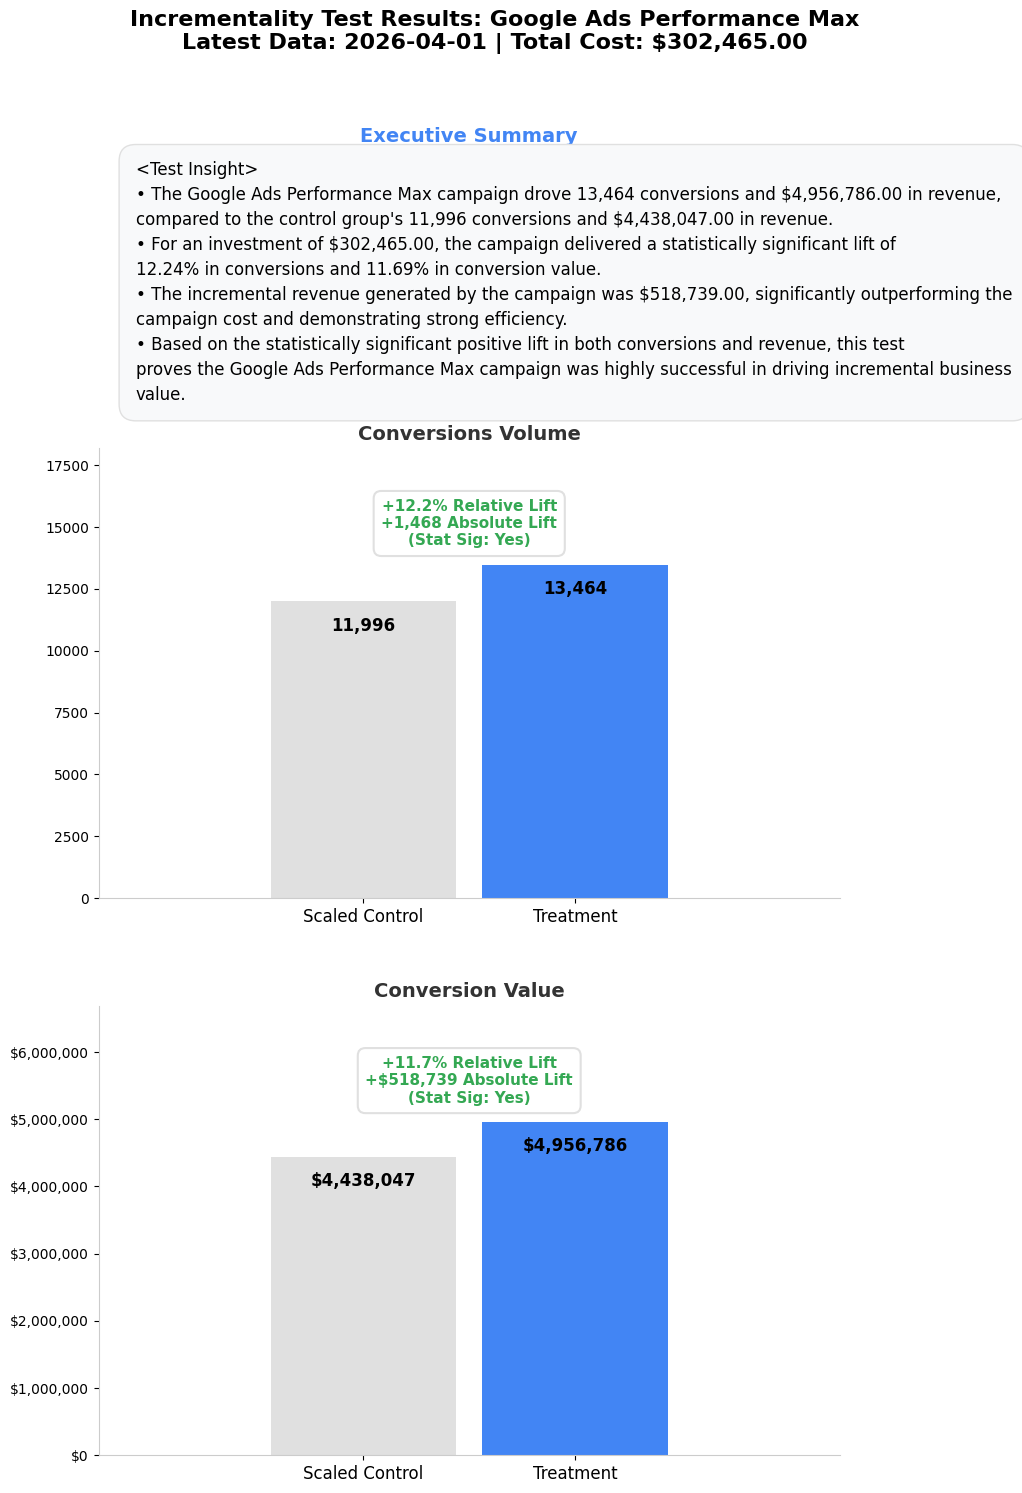


--- Report Preview Completed ---


In [ ]:
# ---------------------------------------------------------
# 4. DATA VISUALIZATION & PDF EXPORT
# ---------------------------------------------------------
print("Generating charts and exporting to PDF...")

pdf_filename = f"{test_media.replace(' ', '_')}_Incrementality_Report.pdf"
pdf = PdfPages(pdf_filename)

fig = plt.figure(figsize=(10, 16))
gs = fig.add_gridspec(3, 1, height_ratios=[1, 2, 2])

fig.suptitle(f'Incrementality Test Results: {test_media}\nLatest Data: {latest_date.strftime("%Y-%m-%d")} | Total Cost: ${total_campaign_cost:,.2f}',
             fontsize=16, fontweight='bold', y=0.96)

# --- Section 1: Executive Summary (Top) ---
ax0 = fig.add_subplot(gs[0])
ax0.axis('off')
ax0.text(0.5, 0.95, "Executive Summary", ha='center', va='top', fontsize=14, fontweight='bold', color=google_blue)

wrapped_lines = []
for line in ai_insight.split('\n'):
    if line.strip():
        wrapped_lines.extend(textwrap.wrap(line, width=100))
wrapped_text = "\n".join(wrapped_lines)

ax0.text(0.05, 0.80, wrapped_text, ha='left', va='top', fontsize=12, linespacing=1.5,
         bbox=dict(boxstyle="round,pad=1", fc="#F8F9FA", ec=google_grey, lw=1))

# Chart variables
groups = ['Scaled Control', 'Treatment']
colors = [google_grey, google_blue]
x_pos = [0.8, 1.2] # Centers the bars closely together around x=1.0
bar_width = 0.35

# --- Section 2: Conversions Chart (Middle) ---
ax1 = fig.add_subplot(gs[1])
bars1 = ax1.bar(x_pos, [control_conv, test_conv], color=colors, width=bar_width)
ax1.set_title('Conversions Volume', fontsize=14, fontweight='bold', color='#333333')
ax1.set_xticks(x_pos)
ax1.set_xticklabels(groups)
ax1.set_xlim(0.3, 1.7)
ax1.set_ylim(0, max(control_conv, test_conv) * 1.35)

# Consistent Annotation Box for Conversions
sign_conv = "+" if lift_conv > 0 else ""
color_conv = google_green if lift_conv > 0 else google_red
box_text_conv = f'{sign_conv}{lift_conv*100:.1f}% Relative Lift\n{sign_conv}{abs_lift_conv:,.0f} Absolute Lift\n(Stat Sig: {"Yes" if is_sig_conv else "No"})'

ax1.annotate(box_text_conv, xy=(1.0, max(control_conv, test_conv) * 1.05),
             ha='center', va='bottom', fontsize=11, color=color_conv, fontweight='bold',
             bbox=dict(boxstyle="round,pad=0.5", fc="white", ec=google_grey, lw=1.5))

for bar in bars1:
    ax1.text(bar.get_x() + bar.get_width()/2, bar.get_height() - (max(control_conv, test_conv)*0.1),
            f'{bar.get_height():,.0f}', ha='center', va='bottom', fontsize=12, color='white' if bar.get_facecolor() == google_blue else 'black', fontweight='bold')

# --- Section 3: Conversion Value Chart (Bottom) ---
ax2 = fig.add_subplot(gs[2])
bars2 = ax2.bar(x_pos, [control_val, test_val], color=colors, width=bar_width)
ax2.set_title('Conversion Value', fontsize=14, fontweight='bold', color='#333333')
ax2.set_xticks(x_pos)
ax2.set_xticklabels(groups)
ax2.set_xlim(0.3, 1.7)
ax2.set_ylim(0, max(control_val, test_val) * 1.35)

vals = ax2.get_yticks()
ax2.set_yticklabels([f'${x:,.0f}' for x in vals])

# Consistent Annotation Box for Value
sign_val = "+" if lift_val > 0 else ""
color_val = google_green if lift_val > 0 else google_red
box_text_val = f'{sign_val}{lift_val*100:.1f}% Relative Lift\n{sign_val}${abs_lift_val:,.0f} Absolute Lift\n(Stat Sig: {"Yes" if is_sig_val else "No"})'

ax2.annotate(box_text_val, xy=(1.0, max(control_val, test_val) * 1.05),
             ha='center', va='bottom', fontsize=11, color=color_val, fontweight='bold',
             bbox=dict(boxstyle="round,pad=0.5", fc="white", ec=google_grey, lw=1.5))

for bar in bars2:
    ax2.text(bar.get_x() + bar.get_width()/2, bar.get_height() - (max(control_val, test_val)*0.1),
            f'${bar.get_height():,.0f}', ha='center', va='bottom', fontsize=12, color='white' if bar.get_facecolor() == google_blue else 'black', fontweight='bold')

# Formatting charts
for ax in [ax1, ax2]:
    ax.spines['top'].set_visible(False)
    ax.spines['right'].set_visible(False)
    ax.spines['left'].set_color('#CCCCCC')
    ax.spines['bottom'].set_color('#CCCCCC')
    ax.tick_params(axis='x', labelsize=12)

plt.tight_layout(rect=[0, 0.03, 1, 0.94])


display(fig) # Display the figure for preview
plt.close(fig) # Close the figure to free memory

print("\n--- Report Preview Completed ---")

In [ ]:
from matplotlib.backends.backend_pdf import PdfPages
from google.colab import files
import matplotlib.pyplot as plt # Make sure plt is imported
import textwrap # Make sure textwrap is imported

print("Generating PDF report...")

pdf_filename = f"{test_media.replace(' ', '_')}_Incrementality_Report.pdf"
pdf = PdfPages(pdf_filename)

# Re-create the figure (charts and insight) for saving to PDF
fig = plt.figure(figsize=(10, 16))
gs = fig.add_gridspec(3, 1, height_ratios=[1, 2, 2])

# Set overarching title
fig.suptitle(f'Incrementality Test Results: {test_media}\nLatest Data: {latest_date.strftime("%Y-%m-%d")} | Total Cost: ${total_campaign_cost:,.2f}',
             fontsize=16, fontweight='bold', y=0.96)

# --- Section 1: Executive Summary (Top) ---
ax0 = fig.add_subplot(gs[0])
ax0.axis('off')
ax0.text(0.5, 0.95, "Executive Summary", ha='center', va='top', fontsize=14, fontweight='bold', color=google_blue)

wrapped_lines = []
for line in ai_insight.split('\n'):
    if line.strip():
        wrapped_lines.extend(textwrap.wrap(line, width=100))
wrapped_text = "\n".join(wrapped_lines)

ax0.text(0.05, 0.80, wrapped_text, ha='left', va='top', fontsize=12, linespacing=1.5,
         bbox=dict(boxstyle="round,pad=1", fc="#F8F9FA", ec=google_grey, lw=1))

# Chart variables
groups = ['Scaled Control', 'Treatment']
colors = [google_grey, google_blue]
x_pos = [0.8, 1.2]
bar_width = 0.4 # Use the updated bar width

# --- Section 2: Conversions Chart (Middle) ---
ax1 = fig.add_subplot(gs[1])
bars1 = ax1.bar(x_pos, [control_conv, test_conv], color=colors, width=bar_width)
ax1.set_title('Conversions Volume', fontsize=14, fontweight='bold', color='#333333')
ax1.set_xticks(x_pos)
ax1.set_xticklabels(groups)
ax1.set_xlim(0.3, 1.7)
ax1.set_ylim(0, max(control_conv, test_conv) * 1.35)

# Consistent Annotation Box for Conversions
sign_conv = "+" if lift_conv > 0 else ""
color_conv = google_green if lift_conv > 0 else google_red
box_text_conv = f'{sign_conv}{lift_conv*100:.1f}% Relative Lift\n{sign_conv}{abs_lift_conv:,.0f} Absolute Lift\n(Stat Sig: {"Yes" if is_sig_conv else "No"})'

ax1.annotate(box_text_conv, xy=(1.0, max(control_conv, test_conv) * 1.05),
             ha='center', va='bottom', fontsize=11, color=color_conv, fontweight='bold',
             bbox=dict(boxstyle="round,pad=0.5", fc="white", ec=google_grey, lw=1.5))

for bar in bars1:
    ax1.text(bar.get_x() + bar.get_width()/2, bar.get_height() - (max(control_conv, test_conv)*0.1),
            f'{bar.get_height():,.0f}', ha='center', va='bottom', fontsize=12, color='white' if bar.get_facecolor() == google_blue else 'black', fontweight='bold')

# --- Section 3: Conversion Value Chart (Bottom) ---
ax2 = fig.add_subplot(gs[2])
bars2 = ax2.bar(x_pos, [control_val, test_val], color=colors, width=bar_width)
ax2.set_title('Conversion Value', fontsize=14, fontweight='bold', color='#333333')
ax2.set_xticks(x_pos)
ax2.set_xticklabels(groups)
ax2.set_xlim(0.3, 1.7)
ax2.set_ylim(0, max(control_val, test_val) * 1.35)

vals = ax2.get_yticks()
ax2.set_yticklabels([f'${x:,.0f}' for x in vals])

# Consistent Annotation Box for Value
sign_val = "+" if lift_val > 0 else ""
color_val = google_green if lift_val > 0 else google_red
box_text_val = f'{sign_val}{lift_val*100:.1f}% Relative Lift\n{sign_val}${abs_lift_val:,.0f} Absolute Lift\n(Stat Sig: {"Yes" if is_sig_val else "No"})'

ax2.annotate(box_text_val, xy=(1.0, max(control_val, test_val) * 1.05),
             ha='center', va='bottom', fontsize=11, color=color_val, fontweight='bold',
             bbox=dict(boxstyle="round,pad=0.5", fc="white", ec=google_grey, lw=1.5))

for bar in bars2:
    ax2.text(bar.get_x() + bar.get_width()/2, bar.get_height() - (max(control_val, test_val)*0.1),
            f'${bar.get_height():,.0f}', ha='center', va='bottom', fontsize=12, color='white' if bar.get_facecolor() == google_blue else 'black', fontweight='bold')

# Formatting charts
for ax in [ax1, ax2]:
    ax.spines['top'].set_visible(False)
    ax.spines['right'].set_visible(False)
    ax.spines['left'].set_color('#CCCCCC')
    ax.spines['bottom'].set_color('#CCCCCC')
    ax.tick_params(axis='x', labelsize=12)

plt.tight_layout(rect=[0, 0.03, 1, 0.94])

pdf.savefig(fig) # Save the figure to PDF
plt.close(fig) # Close the figure after saving

pdf.close() # Close the PDF file
print(f"Success! Report generated: {pdf_filename}")
files.download(pdf_filename) # Download the PDF file

Generating PDF report...
Success! Report generated: Google_Ads_Performance_Max_Incrementality_Report.pdf


<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

In [ ]:

# display(fig) # Display the figure for preview
# plt.close(fig) # Close the figure to free memory

# print("\n--- Report Preview Completed ---")